# Essentials

Python, pandas, NumPy and scikit-learn tools that show up in every notebook of this project.
The topic notebooks (`linear_regression.ipynb`, `decision_trees.ipynb`, ...) explain the **models**;
this one explains the **tools**, so it doesn't have to be repeated in each of them.

When a topic notebook says `(see essentials.ipynb: "...")`, look for the section with that name here.
Every cell runs on its own: change things and run them again to see what happens.

1. Series vs DataFrame
2. X is 2D, y is 1D
3. New data for predict()
4. np.linspace
5. Seeds and random_state

## 1. Series vs DataFrame

Both select the same column. What changes is the **shape** of what you get back:

- `df['col']` returns a **Series**: a single list of values, 1D.
- `df[['col']]` returns a **DataFrame**: a table, 2D, here with only 1 column.

The inner brackets are a normal Python **list** of column names. A list of columns always gives a
table back, even if the list has only one name. It is the same syntax as `df[['col1', 'col2']]`.

In [1]:
import pandas as pd
import numpy as np

df = pd.DataFrame({'YearsExperience': [1.0, 2.5, 4.0, 6.5, 9.0],
                   'Salary':          [24_000, 29_000, 33_000, 39_000, 46_000]})

print(type(df['YearsExperience']).__name__,   df['YearsExperience'].shape)    # Series    (5,)
print(type(df[['YearsExperience']]).__name__, df[['YearsExperience']].shape)  # DataFrame (5, 1)
print(type(df[['YearsExperience', 'Salary']]).__name__, df[['YearsExperience', 'Salary']].shape)

Series (5,)
DataFrame (5, 1)
DataFrame (5, 2)


In [2]:
# Look at how they print: the Series is just values, the DataFrame is a table with a header
print(df['YearsExperience'])
print()
print(df[['YearsExperience']])

0    1.0
1    2.5
2    4.0
3    6.5
4    9.0
Name: YearsExperience, dtype: float64

   YearsExperience
0              1.0
1              2.5
2              4.0
3              6.5
4              9.0


## 2. X is 2D, y is 1D

scikit-learn always sees the data like this:

- **X (features / independent variables)** is a **table**: one row per sample (worker), one column per feature.
  With only one feature it is still a table, with 1 column. That is how the same model can take
  the 4 measurements of iris or the 1 column of years.
- **y (target / dependent variable)** is **one value per sample**, a simple 1D list.

So for `fit()`, X goes with double brackets and y with single brackets.

In [3]:
from sklearn.tree import DecisionTreeRegressor

X = df[['YearsExperience']]   # (5, 1) table
y = df['Salary']              # (5,)   list
model = DecisionTreeRegressor(max_depth=2).fit(X, y)
print("fit() works with X", X.shape, "and y", y.shape)

fit() works with X (5, 1) and y (5,)


In [4]:
# With single brackets, X is 1D and scikit-learn refuses it
try:
    DecisionTreeRegressor().fit(df['YearsExperience'], df['Salary'])
except ValueError as error:
    print("ValueError:", str(error).splitlines()[0])

ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.


### The NumPy version: `reshape(-1, 1)`

In `linear_regression.ipynb` the data was taken out of pandas with `.values` (a NumPy array), and
turned into 2D with `reshape(-1, 1)`: "make it 1 column, and as many rows as needed" (`-1` = work it out).
It does the same job as the double brackets. With pandas the double brackets are cleaner, and the
model also remembers the column name (see section 3).

In [5]:
x = df['YearsExperience'].values
print(x.shape, "->", x.reshape(-1, 1).shape)
print(x.reshape(-1, 1))

(5,) -> (5, 1)
[[1. ]
 [2.5]
 [4. ]
 [6.5]
 [9. ]]


### Quick rule

| Where | Use | Why |
|---|---|---|
| X in `fit()` / `predict()` / `apply()` | `df[['col']]` | scikit-learn needs a 2D table |
| y in `fit()` | `df['col']` | one value per row, 1D |
| `plt.scatter`, `plt.plot`, `.mean()`, comparisons | `df['col']` | they work with a list of values |

## 3. New data for predict()

A model trained with a DataFrame **remembers the column names**. Whatever you pass to `predict()`
later has to look the same: a 2D table with the same columns. That is why new data is built as a
DataFrame with the column `'YearsExperience'`, even for a single worker:

```python
new_worker = pd.DataFrame({'YearsExperience': [4.5]})   # 1 row, 1 column
```

In [6]:
new_worker = pd.DataFrame({'YearsExperience': [4.5]})
print(new_worker.shape)
print("Prediction:", model.predict(new_worker)[0])

# A different column name is an error: the model does not know what 'Years' is
try:
    model.predict(pd.DataFrame({'Years': [4.5]}))
except ValueError as error:
    print("ValueError:", str(error).splitlines()[0])

(1, 1)
Prediction: 31000.0
ValueError: The feature names should match those that were passed during fit.


## 4. np.linspace

`np.linspace(start, stop, num)` gives `num` **evenly spaced** numbers from `start` to `stop`,
**both included**. The gap between them is `(stop - start) / (num - 1)`.

`np.arange(start, stop, step)` is the other way round: you choose the gap, not how many,
and `stop` is **not** included.

In [7]:
print(np.linspace(0, 12, 5))      # 5 numbers, gap = 12 / 4 = 3
print(np.arange(0, 12, 3))        # gap 3, but 12 is left out

grid = np.linspace(0, 12, 1000)   # 1000 numbers, gap = 12 / 999 ≈ 0.012
print(len(grid), grid[:3], grid[-1])

[ 0.  3.  6.  9. 12.]
[0 3 6 9]
1000 [0.         0.01201201 0.02402402] 12.0


### Why it is used to plot a model

If you only predict at the real data points, `plt.plot` joins them with straight lines, and you
don't see what the model does **between** them. A fine grid of made-up inputs asks the model about
every value in the range, so the line shows the model's real shape.

The grid is the **input (X)**, not something being predicted. It goes into a DataFrame with the
training column name (section 3), and `predict()` returns the y for each value.

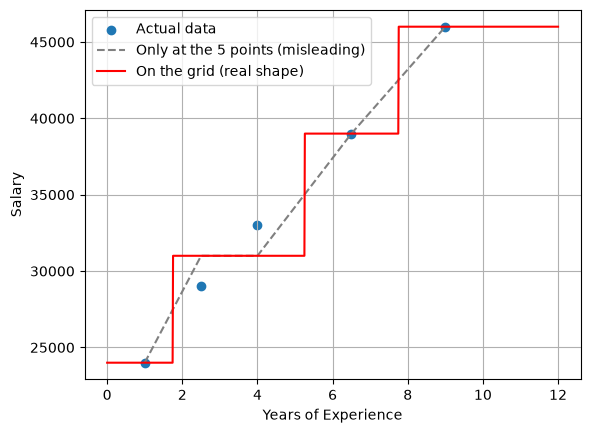

In [8]:
import matplotlib.pyplot as plt

grid = pd.DataFrame({'YearsExperience': np.linspace(0, 12, 1000)})

plt.scatter(df['YearsExperience'], df['Salary'], label='Actual data')
plt.plot(df['YearsExperience'], model.predict(df[['YearsExperience']]),
         color='gray', linestyle='--', label='Only at the 5 points (misleading)')
plt.plot(grid['YearsExperience'], model.predict(grid), color='red', label='On the grid (real shape)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

## 5. Seeds and random_state

Computers generate "random" numbers from a starting number called the **seed**. Same seed,
same numbers, every time. That makes a notebook **reproducible**: your comments ("the first cut is
at 6.15") stay true when you run it again, and anyone else who runs it sees the same results.

The value itself (`42`, `1`, `0`...) has no meaning. `42` is just a popular choice (a joke from
*The Hitchhiker's Guide to the Galaxy*). What matters is that it stays fixed.

The same idea has two names:
- In NumPy: `np.random.default_rng(seed=42)`, to generate data.
- In scikit-learn: `random_state=42`, a parameter of models and functions that use randomness.

In [9]:
print(np.random.default_rng(seed=42).uniform(0, 12, size=3))
print(np.random.default_rng(seed=42).uniform(0, 12, size=3))   # same seed  -> same numbers
print(np.random.default_rng(seed=7).uniform(0, 12, size=3))    # other seed -> other numbers

[ 9.28747258  5.26654128 10.30317504]
[ 9.28747258  5.26654128 10.30317504]
[ 7.5011456  10.76656561  9.30822828]


### What is random in a decision tree?

At each split the tree checks the features **in a random order**. Usually that doesn't matter,
because it keeps the best cut anyway. But when two cuts are **tied** (equally good), the one that
comes first in that order wins, so the seed decides which one you get.

In iris, `petal length` and `petal width` both separate setosa perfectly, so the first question
of the tree depends on `random_state`. With only one feature (like `YearsExperience`) there is
nothing to shuffle, and every seed gives the same tree.

In other places randomness is a core part of the method, and the seed changes the results much more:
`train_test_split` (which rows go to the test set), `RandomForest`, `KMeans`...

In [10]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
for seed in range(6):
    tree = DecisionTreeClassifier(max_depth=1, random_state=seed).fit(iris.data, iris.target)
    first_feature = iris.feature_names[tree.tree_.feature[0]]
    print(f"random_state={seed}: first question uses {first_feature} <= {tree.tree_.threshold[0]:.2f}")

random_state=0: first question uses petal width (cm) <= 0.80
random_state=1: first question uses petal width (cm) <= 0.80
random_state=2: first question uses petal width (cm) <= 0.80
random_state=3: first question uses petal width (cm) <= 0.80
random_state=4: first question uses petal length (cm) <= 2.45
random_state=5: first question uses petal width (cm) <= 0.80
